# The AI Spark Spread
### Who captures the money in one GPU hour: power, compute, or tokens?

Power traders watch the **spark spread**: what electricity sells for minus the cost of the gas burned to make it.
This notebook builds the AI version of that chain, for one GPU hour:

| Layer | What we measure | Unit |
|---|---|---|
| **Power** | Electricity a GPU (and its share of the server + cooling) burns in an hour | $/GPU-hr |
| **Compute** | What a GPU hour rents for | $/GPU-hr |
| **Tokens** | What the tokens that GPU can serve in an hour sell for at API prices | $/GPU-hr |

Two spreads fall out of it:

- **Compute spread** = rental price − power cost → what the GPU owner / neocloud keeps before hardware cost
- **Inference spread** = token revenue − rental price → what the model API provider keeps

**Cases:** NVIDIA H100 (main) and B200 (second), matching Ornn's first two OCPI futures contracts.
**Models:** DeepSeek V3 / R1, gpt-oss-120b, Llama 3.3 70B (open-weight, so many providers price them and public throughput benchmarks exist).
**Window:** 2023 → today, US.

**How this notebook works:** every data source has its own section that fetches (or loads) data and caches it to `data/raw/`.
Anything you collect by hand goes in the CSV templates in `data/manual/`. If a layer has no real data yet, the notebook fills it with
**clearly labeled synthetic placeholder data** so the pipeline runs end to end; every chart built on it is stamped `SYNTHETIC`.
Swap real data in layer by layer.

## 0. Setup

In [1]:
from pathlib import Path
import os, re, json, time, warnings
import datetime as dt

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Project paths (works whether you launch Jupyter from the repo root or from notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC, MANUAL, FIG = (ROOT / "data" / "raw", ROOT / "data" / "processed",
                          ROOT / "data" / "manual", ROOT / "figures")
for p in (RAW, PROC, MANUAL, FIG):
    p.mkdir(parents=True, exist_ok=True)

load_dotenv(ROOT / ".env")
EIA_API_KEY = os.getenv("EIA_API_KEY")
AA_API_KEY = os.getenv("ARTIFICIAL_ANALYSIS_API_KEY")
VAST_API_KEY = os.getenv("VAST_API_KEY")          # optional

START = pd.Period("2023-01", "M")
END = pd.Period(dt.date.today(), "M")
MONTHS = pd.period_range(START, END, freq="M")
TODAY = dt.date.today().isoformat()

# If a layer has no real data, fill it with labeled synthetic data so the pipeline still runs.
USE_SYNTHETIC_FOR_MISSING = True
SYNTHETIC_LAYERS = set()   # filled in as we go; charts read this to stamp themselves

HTTP = requests.Session()
HTTP.headers["User-Agent"] = "spark-spread-research/0.1 (personal research project)"

print("Project root:", ROOT)
print("Window:", START, "->", END, f"({len(MONTHS)} months)")
print("Keys found -> EIA:", bool(EIA_API_KEY), "| Artificial Analysis:", bool(AA_API_KEY))

/Users/maci_mac_mini/Desktop/Spark_Spread/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Project root: /Users/maci_mac_mini/Desktop/Spark_Spread/Spark_Spread
Window: 2023-01 -> 2026-11 (47 months)
Keys found -> EIA: True | Artificial Analysis: True


In [2]:
def get_json(url, cache_file=None, params=None, headers=None, refresh=False, timeout=30):
    # GET a JSON endpoint, caching the response to data/raw/ so reruns don't re-download.
    if cache_file is not None:
        cache_file = RAW / cache_file
        if cache_file.exists() and not refresh:
            return json.loads(cache_file.read_text())
    r = HTTP.get(url, params=params, headers=headers, timeout=timeout)
    r.raise_for_status()
    data = r.json()
    if cache_file is not None:
        cache_file.parent.mkdir(parents=True, exist_ok=True)
        cache_file.write_text(json.dumps(data))
    return data


def append_snapshot(df, path):
    # Append today's snapshot to a running CSV (for live sources like Vast.ai and OpenRouter).
    path = Path(path)
    if path.exists():
        old = pd.read_csv(path)
        df = pd.concat([old, df], ignore_index=True).drop_duplicates()
    df.to_csv(path, index=False)
    return df


def load_manual(name):
    # Load a hand-collected CSV from data/manual/, dropping empty rows.
    df = pd.read_csv(MANUAL / name)
    return df.dropna(how="all")


def stamp(ax, layers_used):
    # Watermark a chart if any layer it uses is synthetic.
    bad = SYNTHETIC_LAYERS & set(layers_used)
    if bad:
        ax.text(0.5, 0.5, "SYNTHETIC\n(" + ", ".join(sorted(bad)) + ")", transform=ax.transAxes,
                ha="center", va="center", fontsize=28, color="red", alpha=0.18, rotation=20)

## 1. Assumptions
Every number here is an input you should verify and log in `sources.md`. Change them here and rerun.

- **Server power, not just the GPU.** A GPU's spec power (700 W for H100 SXM, 1,000 W for B200) leaves out the CPUs, NICs, fans and storage in the server around it.
  We use the 8-GPU server's max power divided by 8 (NVIDIA DGX H100 ≈ 10.2 kW, DGX B200 ≈ 14.3 kW — *verify on NVIDIA's spec sheets*).
- **Load factor.** Servers rarely sit at max power. 0.8 is a working assumption.
- **PUE** (data center overhead for cooling, power conversion). Two scenarios: hyperscale (~1.1, Google/Meta reports) and industry average (~1.5–1.6, Uptime Institute survey).
- **Input:output token ratio.** Providers charge separately for input and output tokens. We use 8 input tokens per output token to match the 8K/1K InferenceX benchmark. Change it to see how the answer moves.
- **Token load factor.** Benchmarks report throughput at full load. Real serving averages less. 0.6 is a working assumption.

In [3]:
GPU_SPECS = {
    # gpu_kw: chip spec power. server_kw: 8-GPU server max power. capex: per 8-GPU server (fill in for v2).
    "H100": {"gpu_kw": 0.700, "server_kw": 10.2, "gpus_per_server": 8, "server_capex_usd": None},
    "B200": {"gpu_kw": 1.000, "server_kw": 14.3, "gpus_per_server": 8, "server_capex_usd": None},
}
LOAD_FACTOR = 0.80
PUE_SCENARIOS = {"hyperscale": 1.10, "industry_avg": 1.56}
PUE_CASE = "industry_avg"

INPUT_PER_OUTPUT = 8.0      # input tokens billed per output token (8K/1K benchmark)
TOKEN_LOAD_FACTOR = 0.60    # average achieved throughput / benchmark throughput

# Power price series to use: EIA state ("US" = national average) and sector ("IND" industrial, "COM" commercial)
POWER_STATE, POWER_SECTOR = "US", "IND"

# v2: hardware cost
INCLUDE_HARDWARE = False
HW_LIFE_YEARS = 5
HW_UTILIZATION = 0.70

GPUS = list(GPU_SPECS)

def kw_per_gpu(gpu):
    s = GPU_SPECS[gpu]
    return s["server_kw"] / s["gpus_per_server"]

pd.DataFrame({g: {"chip kW": s["gpu_kw"], "all-in kW per GPU (server/8)": kw_per_gpu(g),
                  "kWh drawn per GPU-hr (x load x PUE)": kw_per_gpu(g) * LOAD_FACTOR * PUE_SCENARIOS[PUE_CASE]}
              for g, s in GPU_SPECS.items()}).round(3)

,H100,B200
chip kW,0.700,1.000
all-in kW per GPU (server/8),1.275,1.788
kWh drawn per GPU-hr (x load x PUE),1.591,2.231


### Models
OpenRouter IDs change, so each model is matched with a pattern. **Check the printed matches in section 4** and tighten the patterns if needed.

**History tip:** DeepSeek V3, R1 and Llama 3.3 launched in Dec 2024–Jan 2025, and gpt-oss-120b later, so they can't cover 2023–24 on their own.
`MODEL_LINEAGE` stitches each model onto its predecessors (for example Llama 2 70B → Llama 3.1 70B → Llama 3.3 70B) so you get one "70B-class" price series back to 2023.

In [4]:
MODELS = {
    "DeepSeek-V3":   r"^deepseek/deepseek-(chat|v3)",
    "DeepSeek-R1":   r"^deepseek/deepseek-r1(?!.*distill)",
    "gpt-oss-120b":  r"^openai/gpt-oss-120b",
    "Llama-3.3-70B": r"^meta-llama/llama-3\.3-70b-instruct",
}
# Predecessors used to extend each series back in time (oldest first). Edit freely.
MODEL_LINEAGE = {
    "Llama-3.3-70B": ["Llama-2-70B", "Llama-3-70B", "Llama-3.1-70B", "Llama-3.3-70B"],
    "DeepSeek-V3":   ["DeepSeek-V2", "DeepSeek-V2.5", "DeepSeek-V3"],
    "DeepSeek-R1":   ["DeepSeek-R1"],
    "gpt-oss-120b":  ["gpt-oss-120b"],
}
MODEL_NAMES = list(MODELS)

## 2. Power layer — $ per GPU hour of electricity

**Source:** EIA API v2, `electricity/retail-sales`: monthly average retail price (cents/kWh) by state and sector.
Get a free key at https://www.eia.gov/opendata/ and put it in `.env` as `EIA_API_KEY=...`.

States worth pulling besides the US average: data center hubs like VA (Northern Virginia), TX, GA, AZ, OR.

**Cost per GPU hour** = all-in kW per GPU × load factor × PUE × $/kWh

In [5]:
EIA_STATES = ["US", "VA", "TX", "GA", "AZ", "OR"]
EIA_SECTORS = ["IND", "COM"]

def fetch_eia_retail_prices(refresh=False, timeout=90, retries=3):
    # One small request per state x sector, with retries. EIA's API is slow on big multi-facet queries.
    cache = RAW / "eia_retail_prices.csv"
    if cache.exists() and not refresh:
        df = pd.read_csv(cache)
        df["month"] = pd.PeriodIndex(df["month"], freq="M")
        return df
    url = "https://api.eia.gov/v2/electricity/retail-sales/data/"
    frames = []
    for state in EIA_STATES:
        for sector in EIA_SECTORS:
            params = [("api_key", EIA_API_KEY), ("frequency", "monthly"), ("data[0]", "price"),
                      ("facets[stateid][]", state), ("facets[sectorid][]", sector),
                      ("start", str(START)), ("sort[0][column]", "period"),
                      ("sort[0][direction]", "asc"), ("length", 5000)]
            for attempt in range(1, retries + 1):
                try:
                    r = HTTP.get(url, params=params, timeout=timeout)
                    r.raise_for_status()
                    rows = r.json()["response"]["data"]
                    frames.append(pd.DataFrame(rows))
                    print(f"  {state} {sector}: {len(rows)} months")
                    break
                except Exception as e:
                    print(f"  {state} {sector}: attempt {attempt} failed ({type(e).__name__})")
                    time.sleep(3 * attempt)
            time.sleep(0.5)
    if not frames:
        raise RuntimeError("No EIA data returned")
    df = pd.concat(frames, ignore_index=True)
    df["cents_per_kwh"] = pd.to_numeric(df["price"], errors="coerce")
    df["month"] = pd.PeriodIndex(df["period"], freq="M")
    df = df[["month", "stateid", "sectorid", "cents_per_kwh"]]
    df.to_csv(cache, index=False)
    return df

power_prices = None
if EIA_API_KEY:
    try:
        power_prices = fetch_eia_retail_prices()
        print(f"EIA: {len(power_prices)} rows, {power_prices.month.min()} -> {power_prices.month.max()}")
    except Exception as e:
        print("EIA fetch failed:", e)
else:
    print("No EIA_API_KEY in .env")

if power_prices is None and USE_SYNTHETIC_FOR_MISSING:
    SYNTHETIC_LAYERS.add("power")
    m = np.arange(len(MONTHS))
    base = {"IND": 8.2, "COM": 12.6}
    power_prices = pd.DataFrame([
        {"month": p, "stateid": "US", "sectorid": sec,
         "cents_per_kwh": base[sec] * (1 + 0.01 * i / 12) * (1 + 0.06 * np.sin(2 * np.pi * (p.month - 4) / 12))}
        for sec in EIA_SECTORS for i, p in zip(m, MONTHS)])
    print("Using SYNTHETIC power prices")

power_prices.pivot_table(index="month", columns=["stateid", "sectorid"], values="cents_per_kwh").tail()

EIA: 540 rows, 2023-01 -> 2026-09


stateid      AZ           GA            OR          TX           US           VA       
sectorid    COM   IND    COM    IND    COM   IND   COM   IND    COM   IND    COM    IND
month                                                                                  
2026-05   12.15  7.54  10.88   7.04  10.61  8.55  8.24  6.44  13.52  8.68  10.84  10.52
2026-06   12.47  7.73  11.91   8.86  10.59  8.83  8.61  6.53  14.18  9.16  10.99   9.34
2026-07   13.12  9.35  12.54  10.03  10.60  8.92  8.47  7.07  14.53  9.77  11.68  10.07
2026-08   13.05  9.73  13.81  13.05  10.72  8.75  8.96  7.21  14.47  9.64  11.14   9.98
2026-09   12.02  7.95  12.19   8.81   9.71  8.51  8.96  6.99  14.27  9.52  11.50   9.86

**Optional: wholesale power (ERCOT / PJM).** Retail tariffs are what most data centers pay, but large sites buy closer to wholesale.
The ISO data portals are fiddly to automate, so download monthly averages by hand into `data/manual/wholesale_power.csv`
(`month,market,usd_per_mwh,source_url`) and set `USE_WHOLESALE = True`.

In [6]:
USE_WHOLESALE = False
WHOLESALE_MARKET = "ERCOT"

def power_usd_per_kwh():
    # Monthly $/kWh series used downstream.
    if USE_WHOLESALE:
        w = load_manual("wholesale_power.csv")
        w = w[w.market == WHOLESALE_MARKET].copy()
        w["month"] = pd.PeriodIndex(w["month"], freq="M")
        return w.groupby("month")["usd_per_mwh"].mean() / 1000
    s = power_prices.query("stateid == @POWER_STATE and sectorid == @POWER_SECTOR")
    return s.groupby("month")["cents_per_kwh"].mean() / 100

usd_kwh = power_usd_per_kwh().reindex(MONTHS).interpolate(limit_direction="both")
pue = PUE_SCENARIOS[PUE_CASE]
power_cost = pd.DataFrame({g: usd_kwh * kw_per_gpu(g) * LOAD_FACTOR * pue for g in GPUS})
power_cost.index.name = "month"
print(f"Power cost per GPU-hr ({POWER_STATE} {POWER_SECTOR}, PUE {pue}):")
power_cost.tail(3).round(4)

Power cost per GPU-hr (US IND, PUE 1.56):


,H100,B200
month,,
2026-09,0.1515,0.2124
2026-10,0.1515,0.2124
2026-11,0.1515,0.2124


## 3. Compute layer — $ per GPU hour of rental

Three inputs, combined into one monthly series per GPU:

1. **Historical list prices** from Wayback Machine snapshots of neocloud pricing pages (Lambda, CoreWeave, RunPod, AWS).
   Pricing pages change layout and many render prices with JavaScript, so scraping them reliably is not realistic.
   The helper below pulls one snapshot per month and **suggests** candidate prices; you check them and copy the good ones into
   `data/manual/gpu_list_prices.csv`. That hand-checked file is what the analysis uses.
2. **Vast.ai marketplace** (live offers from its public API). Run this cell regularly (or on a schedule) to build your own history.
3. **Epoch AI ML hardware dataset** for launch prices and specs (used for hardware cost in v2). Download the CSV from epoch.ai/data into `data/raw/`.

> Caveat worth raising with Ornn: everything here is **list or asking prices**. OCPI is built from **settled trades**. The gap between the two is a finding in itself.
>
> Ornn's and Silicon Data's public price displays are used only as a **cross-check** (section 3d), credited, and never as an input.

In [7]:
PRICING_PAGES = {
    "Lambda":    ["lambdalabs.com/service/gpu-cloud", "lambda.ai/pricing"],
    "CoreWeave": ["coreweave.com/pricing"],
    "RunPod":    ["runpod.io/pricing", "runpod.io/gpu-instance/pricing"],
    "AWS-p5":    ["aws.amazon.com/ec2/instance-types/p5/"],
}
GPU_PATTERNS = {"H100": r"H100", "B200": r"B200"}

def wayback_monthly_snapshots(url, start_year=2023):
    # One successful snapshot timestamp per month for a URL, via the Wayback CDX API.
    rows = get_json("https://web.archive.org/cdx/search/cdx",
                    cache_file=f"wayback/cdx_{re.sub(r'[^a-z0-9]+', '_', url.lower())}.json",
                    params={"url": url, "output": "json", "from": str(start_year),
                            "filter": "statuscode:200", "collapse": "timestamp:6", "fl": "timestamp,original"})
    return pd.DataFrame(rows[1:], columns=rows[0]) if rows else pd.DataFrame(columns=["timestamp", "original"])

def wayback_fetch(ts, url):
    # Fetch a raw archived page ('id_' = original bytes, no Wayback toolbar), cached to disk.
    f = RAW / "wayback" / re.sub(r"[^a-z0-9]+", "_", url.lower()) / f"{ts}.html"
    if f.exists():
        return f.read_text(errors="ignore")
    r = HTTP.get(f"https://web.archive.org/web/{ts}id_/{url}", timeout=60)
    r.raise_for_status()
    f.parent.mkdir(parents=True, exist_ok=True)
    f.write_text(r.text)
    time.sleep(1)   # be polite to archive.org
    return r.text

def price_candidates(html, gpu_regex, window=250):
    # Dollar amounts appearing shortly after each GPU mention. Suggestions only: verify by eye.
    text = re.sub(r"<script.*?</script>|<style.*?</style>", " ", html, flags=re.S | re.I)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\s+", " ", text)
    out = []
    for m in re.finditer(gpu_regex, text):
        snippet = text[m.start(): m.start() + window]
        for d in re.findall(r"\$\s?(\d{1,3}(?:\.\d{1,3})?)", snippet):
            out.append({"usd": float(d), "context": snippet[:160]})
    return out

def scan_wayback(providers=PRICING_PAGES, max_snapshots=None):
    found = []
    for provider, urls in providers.items():
        for url in urls:
            try:
                snaps = wayback_monthly_snapshots(url)
            except Exception as e:
                print(f"  {provider} {url}: CDX failed ({e})"); continue
            print(f"{provider} {url}: {len(snaps)} monthly snapshots")
            for ts in snaps.timestamp[:max_snapshots]:
                try:
                    html = wayback_fetch(ts, url)
                except Exception as e:
                    print("   fetch failed", ts, e); continue
                for gpu, rx in GPU_PATTERNS.items():
                    for c in price_candidates(html, rx):
                        found.append({"date": pd.to_datetime(ts[:8]).date(), "provider": provider, "gpu": gpu,
                                      "candidate_usd": c["usd"], "context": c["context"],
                                      "snapshot_url": f"https://web.archive.org/web/{ts}/{url}"})
    df = pd.DataFrame(found)
    if len(df):
        df.to_csv(PROC / "wayback_price_candidates.csv", index=False)
        print(f"Saved {len(df)} candidates -> data/processed/wayback_price_candidates.csv (review, then copy to data/manual/gpu_list_prices.csv)")
    return df

RUN_WAYBACK_SCAN = False   # set True to run; start with max_snapshots=3 to test
if RUN_WAYBACK_SCAN:
    candidates = scan_wayback(max_snapshots=3)
    display(candidates.head(20))

In [8]:
# 3b. Vast.ai live marketplace snapshot
def fetch_vast_offers():
    q = {"gpu_name": {"in": ["H100 SXM", "H100 NVL", "H100 PCIE", "B200"]},
         "rentable": {"eq": True}, "rented": {"eq": False}, "type": "on-demand", "limit": 1000}
    headers = {"Authorization": f"Bearer {VAST_API_KEY}"} if VAST_API_KEY else None
    data = get_json("https://console.vast.ai/api/v0/bundles/", params={"q": json.dumps(q)}, headers=headers)
    df = pd.json_normalize(data.get("offers", []))
    keep = ["id", "gpu_name", "num_gpus", "dph_total", "geolocation", "reliability2", "verification"]
    df = df[[c for c in keep if c in df.columns]].copy()
    df["usd_per_gpu_hr"] = df["dph_total"] / df["num_gpus"]
    df["gpu"] = df["gpu_name"].str.extract(r"(H100|B200)")[0]
    df["snapshot_date"] = TODAY
    return df

try:
    vast = fetch_vast_offers()
    vast_all = append_snapshot(vast, RAW / "vast_snapshots.csv")
    print(f"Vast.ai: {len(vast)} offers today; {vast_all.snapshot_date.nunique()} snapshot days on file")
    display(vast.groupby("gpu_name")["usd_per_gpu_hr"].describe().round(2))
except Exception as e:
    print("Vast.ai fetch failed:", e)
    vast_all = pd.read_csv(RAW / "vast_snapshots.csv") if (RAW / "vast_snapshots.csv").exists() else pd.DataFrame()

Vast.ai: 17 offers today; 1 snapshot days on file


,count,mean,std,min,25%,50%,75%,max
gpu_name,,,,,,,,
B200,6.0,10.29,1.21,8.28,9.92,10.63,10.63,11.89
H100 NVL,2.0,3.03,0.68,2.54,2.78,3.03,3.27,3.51
H100 PCIE,3.0,2.45,0.14,2.32,2.38,2.44,2.52,2.60
H100 SXM,6.0,2.64,1.37,1.73,1.75,1.79,3.63,4.56


In [9]:
# 3c. Combine hand-checked list prices + Vast snapshots into one monthly rental series per GPU
list_prices = load_manual("gpu_list_prices.csv")
list_prices = list_prices[list_prices.pricing_type.fillna("on-demand").eq("on-demand")] if len(list_prices) else list_prices

frames = []
if len(list_prices):
    lp = list_prices.assign(month=pd.PeriodIndex(pd.to_datetime(list_prices["date"]), freq="M"), source="list")
    frames.append(lp[["month", "gpu", "price_usd_per_gpu_hr", "source"]])
if len(vast_all):
    va = vast_all.dropna(subset=["gpu"]).assign(month=lambda d: pd.PeriodIndex(pd.to_datetime(d.snapshot_date), freq="M"), source="vast")
    frames.append(va.rename(columns={"usd_per_gpu_hr": "price_usd_per_gpu_hr"})[["month", "gpu", "price_usd_per_gpu_hr", "source"]])

rental_obs = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(columns=["month", "gpu", "price_usd_per_gpu_hr", "source"])
print(rental_obs.groupby(["gpu", "source"]).size().rename("observations") if len(rental_obs) else "No rental observations yet")

if rental_obs.gpu.nunique() < len(GPUS) and USE_SYNTHETIC_FOR_MISSING:
    SYNTHETIC_LAYERS.add("compute")
    synth = []
    for p in MONTHS:
        t = (p - START).n / 12                                  # years since Jan 2023
        synth.append({"month": p, "gpu": "H100", "price_usd_per_gpu_hr": 1.9 + 2.8 * np.exp(-1.1 * t), "source": "SYNTHETIC"})
        if p >= pd.Period("2025-02", "M"):
            t2 = (p - pd.Period("2025-02", "M")).n / 12
            synth.append({"month": p, "gpu": "B200", "price_usd_per_gpu_hr": 3.2 + 3.0 * np.exp(-1.0 * t2), "source": "SYNTHETIC"})
    synth = pd.DataFrame(synth)
    missing = [g for g in GPUS if g not in set(rental_obs.gpu)]
    rental_obs = pd.concat([rental_obs, synth[synth.gpu.isin(missing)]], ignore_index=True)
    print("Using SYNTHETIC rental prices for:", missing)

rental_obs["price_usd_per_gpu_hr"] = pd.to_numeric(rental_obs["price_usd_per_gpu_hr"], errors="coerce")
# Median across providers each month; fill gaps of up to 3 months, never before a GPU's first observation
rental = (rental_obs.groupby(["month", "gpu"])["price_usd_per_gpu_hr"].median()
          .unstack("gpu").reindex(MONTHS).interpolate(limit=3, limit_area="inside"))
rental = rental.reindex(columns=GPUS)
rental.index.name = "month"
rental.dropna(how="all").tail(4).round(2)

gpu   source
B200  vast      22
H100  vast      65
Name: observations, dtype: int64


gpu,H100,B200
month,,
2026-11,2.54,10.63


In [10]:
# 3d. Cross-check (credit only, never an input): type in today's public H100/B200 figures from Ornn and Silicon Data.
CROSS_CHECK = {
    # "Ornn OCPI (ornn.com, accessed YYYY-MM-DD)": {"H100": None, "B200": None},
    # "Silicon Data SDH100RT (accessed YYYY-MM-DD)": {"H100": None},
}
latest = rental.ffill().iloc[-1]
rows = [{"source": "This notebook (list/asking prices)", **latest.round(2).to_dict()}]
rows += [{"source": k, **v} for k, v in CROSS_CHECK.items()]
pd.DataFrame(rows).set_index("source")

,H100,B200
source,,
This notebook (list/asking prices),2.54,10.63


## 4. Token layer — $ per million tokens, and tokens per second per GPU

**Prices**
1. **OpenRouter** `/api/v1/models` (no key) lists every model; `/api/v1/models/{id}/endpoints` gives each provider's input/output price.
   Run it regularly to build history going forward.
2. **Wayback snapshots of the OpenRouter models API** for history. The JSON endpoint itself has been archived on some dates; the helper tries it.
3. **Artificial Analysis** (free key) for price and output speed by provider.
4. **Epoch AI LLM inference price trends** for the long-run picture (CSV download into `data/raw/`).
5. Anything you collect by hand goes in `data/manual/token_prices_history.csv`.

**Throughput** comes from **SemiAnalysis InferenceX** (tokens/sec per GPU by chip, model, precision and concurrency). Copy the
configurations you use into `data/manual/throughput.csv`. Record precision, framework, input/output lengths and concurrency: throughput
per GPU can move 5–10x between a latency-focused and a throughput-focused setting, so pick one setting and use it consistently.

In [11]:
# 4a. OpenRouter: current prices per provider
def openrouter_snapshot():
    models = get_json("https://openrouter.ai/api/v1/models", f"openrouter/models_{TODAY}.json")["data"]
    rows = []
    for name, rx in MODELS.items():
        ids = [m["id"] for m in models if re.search(rx, m["id"])]
        print(f"{name:15s} matched: {ids}")
        for mid in ids:
            try:
                ep = get_json(f"https://openrouter.ai/api/v1/models/{mid}/endpoints",
                              f"openrouter/endpoints_{mid.replace('/', '__')}_{TODAY}.json")["data"]
            except Exception as e:
                print("   endpoints failed", mid, e); continue
            for e in ep.get("endpoints", []):
                pr = e.get("pricing", {})
                rows.append({"date": TODAY, "model": name, "openrouter_id": mid,
                             "provider": e.get("provider_name"), "quantization": e.get("quantization"),
                             "usd_per_m_input": float(pr.get("prompt", "nan")) * 1e6,
                             "usd_per_m_output": float(pr.get("completion", "nan")) * 1e6,
                             "source": "openrouter"})
    return pd.DataFrame(rows)

try:
    or_today = openrouter_snapshot()
    or_all = append_snapshot(or_today, RAW / "openrouter_price_snapshots.csv")
    display(or_today.groupby("model")[["usd_per_m_input", "usd_per_m_output"]].median().round(3))
except Exception as e:
    print("OpenRouter fetch failed:", e)
    or_all = pd.read_csv(RAW / "openrouter_price_snapshots.csv") if (RAW / "openrouter_price_snapshots.csv").exists() else pd.DataFrame()

DeepSeek-V3     matched: ['deepseek/deepseek-v3.2', 'deepseek/deepseek-v3.2-exp', 'deepseek/deepseek-v3.1-terminus', 'deepseek/deepseek-chat-v3.1', 'deepseek/deepseek-chat-v3-0324', 'deepseek/deepseek-chat']
DeepSeek-R1     matched: ['deepseek/deepseek-r1-0528']
gpt-oss-120b    matched: ['openai/gpt-oss-120b', 'openai/gpt-oss-120b:batch']
Llama-3.3-70B   matched: ['meta-llama/llama-3.3-70b-instruct']


,usd_per_m_input,usd_per_m_output
model,,
DeepSeek-R1,0.500,2.180
DeepSeek-V3,0.270,0.975
Llama-3.3-70B,0.293,0.710
gpt-oss-120b,0.100,0.550


In [12]:
# 4b. Wayback history of the OpenRouter models API (top-level price per model, not per provider)
def openrouter_wayback_history(max_snapshots=None):
    snaps = wayback_monthly_snapshots("openrouter.ai/api/v1/models")
    print(f"{len(snaps)} archived monthly copies of openrouter.ai/api/v1/models")
    rows = []
    for ts in snaps.timestamp[:max_snapshots]:
        try:
            data = json.loads(wayback_fetch(ts, "openrouter.ai/api/v1/models"))["data"]
        except Exception:
            continue
        for m in data:
            rows.append({"date": pd.to_datetime(ts[:8]).date(), "openrouter_id": m["id"],
                         "usd_per_m_input": float(m["pricing"]["prompt"]) * 1e6,
                         "usd_per_m_output": float(m["pricing"]["completion"]) * 1e6})
    df = pd.DataFrame(rows)
    if len(df):
        df.to_csv(RAW / "openrouter_wayback_prices.csv", index=False)
    return df

RUN_OR_WAYBACK = False
if RUN_OR_WAYBACK:
    or_hist = openrouter_wayback_history()
    display(or_hist.head())

In [13]:
# 4c. Artificial Analysis: price + output speed by model (free key; attribution to artificialanalysis.ai required)
# The old /api/v2/data/llms/models endpoint is retired (HTTP 410). Free keys use /api/v2/language/models/free (paginated).
def fetch_artificial_analysis(max_pages=20):
    url = "https://artificialanalysis.ai/api/v2/language/models/free"
    frames, page = [], 1
    while page <= max_pages:
        data = get_json(url, f"artificial_analysis/models_free_{TODAY}_p{page}.json",
                        params={"page": page}, headers={"x-api-key": AA_API_KEY}, timeout=60)
        frames.append(pd.json_normalize(data.get("data", [])))
        if not data.get("pagination", {}).get("has_more"):
            break
        page += 1
    df = pd.concat(frames, ignore_index=True)
    df["date"] = TODAY
    return df

def aa_tidy(df):
    # Pick whichever price / speed fields this tier returns (field names have changed over time).
    def first(*cols):
        for c in cols:
            if c in df.columns:
                return df[c]
        return pd.Series(np.nan, index=df.index)
    return pd.DataFrame({
        "date": df["date"], "name": first("name"), "slug": first("slug"),
        "creator": first("model_creator.name"),
        "usd_per_m_input": pd.to_numeric(first("pricing.price_1m_input_tokens"), errors="coerce"),
        "usd_per_m_output": pd.to_numeric(first("pricing.price_1m_output_tokens"), errors="coerce"),
        "output_tok_s": pd.to_numeric(first("performance_v3.mean_output_tokens_per_second",
                                            "performance.median_output_tokens_per_second"), errors="coerce"),
    })

aa = pd.DataFrame()
if AA_API_KEY:
    try:
        aa = aa_tidy(fetch_artificial_analysis())
        append_snapshot(aa, RAW / "artificial_analysis_snapshots.csv")
        mask = aa["name"].astype(str).str.contains(r"DeepSeek|gpt-oss|Llama 3\.3", case=False)
        print(f"Artificial Analysis: {len(aa)} models; matches for our set:")
        display(aa[mask].sort_values("name"))
    except Exception as e:
        print("Artificial Analysis fetch failed:", e)
else:
    print("No ARTIFICIAL_ANALYSIS_API_KEY in .env (optional)")

Artificial Analysis: 766 models; matches for our set:


,date,name,slug,creator,usd_per_m_input,usd_per_m_output,output_tok_s
596,2026-11-25,DeepSeek Coder V2 Lite Instruct,deepseek-coder-v2-lite,DeepSeek,NaN,NaN,NaN
372,2026-11-25,DeepSeek LLM 67B Chat (V1),deepseek-llm-67b-chat,DeepSeek,NaN,NaN,NaN
50,2026-11-25,DeepSeek R1 (Jan '25),deepseek-r1-0120,DeepSeek,2.0000,4.0000,132.84
505,2026-11-25,DeepSeek R1 0528 (May '25),deepseek-r1,DeepSeek,1.8500,2.7500,24.07
302,2026-11-25,DeepSeek R1 0528 Qwen3 8B,deepseek-r1-qwen3-8b,DeepSeek,NaN,NaN,NaN
231,2026-11-25,DeepSeek R1 Distill Llama 70B,deepseek-r1-distill-llama-70b,DeepSeek,0.7000,1.4000,NaN
51,2026-11-25,DeepSeek R1 Distill Llama 8B,deepseek-r1-distill-llama-8b,DeepSeek,NaN,NaN,NaN
212,2026-11-25,DeepSeek R1 Distill Qwen 1.5B,deepseek-r1-distill-qwen-1-5b,DeepSeek,NaN,NaN,NaN
542,2026-11-25,DeepSeek R1 Distill Qwen 14B,deepseek-r1-distill-qwen-14b,DeepSeek,NaN,NaN,NaN
677,2026-11-25,DeepSeek R1 Distill Qwen 32B,deepseek-r1-distill-qwen-32b,DeepSeek,NaN,NaN,NaN


In [14]:
# 4d. Assemble a monthly blended token price per model
def lineage_map():
    # Map every predecessor name to the series it extends.
    return {old: new for new, olds in MODEL_LINEAGE.items() for old in olds}

price_frames = []
manual_tp = load_manual("token_prices_history.csv")
if len(manual_tp):
    price_frames.append(manual_tp.assign(source=manual_tp.get("source", "manual")))
if len(or_all):
    price_frames.append(or_all[["date", "model", "provider", "usd_per_m_input", "usd_per_m_output", "source"]])

token_obs = pd.concat(price_frames, ignore_index=True) if price_frames else pd.DataFrame(
    columns=["date", "model", "provider", "usd_per_m_input", "usd_per_m_output", "source"])
token_obs["series"] = token_obs["model"].map(lineage_map()).fillna(token_obs["model"])

if token_obs.series.nunique() < len(MODEL_NAMES) and USE_SYNTHETIC_FOR_MISSING:
    SYNTHETIC_LAYERS.add("tokens")
    # Synthetic: prices fall over time, roughly like the long-run trend, per series.
    start_out = {"DeepSeek-V3": 2.2, "DeepSeek-R1": 2.6, "gpt-oss-120b": 0.9, "Llama-3.3-70B": 1.6}
    floor_out = {"DeepSeek-V3": 0.9, "DeepSeek-R1": 2.0, "gpt-oss-120b": 0.5, "Llama-3.3-70B": 0.35}
    first = {"DeepSeek-R1": pd.Period("2025-01", "M"), "gpt-oss-120b": pd.Period("2025-08", "M")}
    synth = []
    for s in MODEL_NAMES:
        for p in MONTHS:
            if p < first.get(s, START):
                continue
            t = (p - START).n / 12
            out = floor_out[s] + (start_out[s] - floor_out[s]) * np.exp(-0.9 * t)
            synth.append({"date": p.to_timestamp().date(), "model": s, "series": s, "provider": "SYNTHETIC",
                          "usd_per_m_input": out / 3.5, "usd_per_m_output": out, "source": "SYNTHETIC"})
    synth = pd.DataFrame(synth)
    missing = [s for s in MODEL_NAMES if s not in set(token_obs.series)]
    token_obs = pd.concat([token_obs, synth[synth.series.isin(missing)]], ignore_index=True)
    print("Using SYNTHETIC token prices for:", missing)

for c in ["usd_per_m_input", "usd_per_m_output"]:
    token_obs[c] = pd.to_numeric(token_obs[c], errors="coerce")
token_obs["month"] = pd.PeriodIndex(pd.to_datetime(token_obs["date"]), freq="M")
# $ earned per 1M OUTPUT tokens, counting the input tokens billed alongside them
token_obs["usd_per_m_output_blended"] = token_obs["usd_per_m_output"] + INPUT_PER_OUTPUT * token_obs["usd_per_m_input"]

token_price = (token_obs.groupby(["month", "series"])["usd_per_m_output_blended"].median()
               .unstack("series").reindex(MONTHS).interpolate(limit=3, limit_area="inside"))
token_price = token_price.reindex(columns=MODEL_NAMES)
token_price.index.name = "month"
print(f"Blended $ per 1M output tokens (incl. {INPUT_PER_OUTPUT:g}M input tokens):")
token_price.dropna(how="all").tail(4).round(3)

Blended $ per 1M output tokens (incl. 8M input tokens):


series,DeepSeek-V3,DeepSeek-R1,gpt-oss-120b,Llama-3.3-70B
month,,,,
2026-11,3.044,6.18,1.19,2.26


In [15]:
# 4e. Throughput: output tokens/sec per GPU, by GPU x model (from InferenceX, entered in data/manual/throughput.csv)
# InferenceX exports: drop the CSVs you download from the InferenceX table view into data/raw/inferencex/.
# For each chip, model and run date we read output tok/s per chip at TARGET_INTERACTIVITY, interpolating
# between concurrency points and keeping the best TP (parallelism) config at that speed.
TARGET_INTERACTIVITY = 50          # median tok/s per user
INFERENCEX_HW = {"h100": "H100", "b200": "B200"}
INFERENCEX_MODELS = {              # InferenceX model name (lowercase) -> our model name
    "gpt-oss-120b": "gpt-oss-120b",
    "deepseek-r1-0528": "DeepSeek-R1",
    "llama-3.3-70b-instruct-fp8": "Llama-3.3-70B",
}
# One precision per model, the same on both GPUs
PRECISION_PREF = {"gpt-oss-120b": "fp4", "DeepSeek-R1": "fp8", "Llama-3.3-70B": "fp8"}
# Models with no InferenceX run of their own, borrowed from a same-architecture model (labeled in `source`)
THROUGHPUT_PROXY = {"DeepSeek-V3": "DeepSeek-R1"}   # V3 and R1 share the 671B MoE architecture

# Spec decoding (e.g. MTP) boosts throughput; keep it out of the base case and add it later as a sensitivity.
ALLOW_SPEC_DECODING = False
# One serving framework per model so H100 vs B200 is like for like (DeepSeek is only on Dynamo setups for H100).
FRAMEWORK_PREF = {"DeepSeek-R1": "dynamo-trt", "Llama-3.3-70B": "vllm", "gpt-oss-120b": "vllm"}
DEFAULT_FRAMEWORK = "vllm"

CONFIG_COLS = ["TP", "EP", "DP Attention", "Disaggregated", "Num Prefill Chips", "Num Decode Chips", "Spec Decoding", "Is Multinode"]

def add_output_per_gpu(df):
    # InferenceX divides OUTPUT throughput by DECODE chips only for disaggregated (prefill/decode split) setups.
    # Convert to output tok/s per GPU across ALL chips the setup uses, so it compares with non-split setups.
    df = df.copy()
    out = df["Output Token Throughput per Chip (tok/s/chip)"].astype(float)
    disagg = df["Disaggregated"].astype(str).str.lower().eq("true")
    pre = pd.to_numeric(df["Num Prefill Chips"], errors="coerce")
    dec = pd.to_numeric(df["Num Decode Chips"], errors="coerce")
    df["output_tok_s_per_gpu_all"] = np.where(disagg & pre.notna() & dec.notna(), out * dec / (pre + dec), out)
    return df

def inferencex_at_interactivity(df, target):
    # Best achievable output tok/s per GPU at `target` interactivity, across ALL setups (the Pareto frontier,
    # same idea as InferenceX's own charts). Interpolated in log space between the two frontier points around target.
    pts = df[["Median Interactivity (tok/s/user)", "output_tok_s_per_gpu_all", "Concurrency", "Run URL"]].dropna()
    pts = pts.sort_values("Median Interactivity (tok/s/user)", ascending=False)
    frontier, best_y = [], -np.inf
    for _, r in pts.iterrows():                       # walking from fastest-per-user to slowest
        if r["output_tok_s_per_gpu_all"] > best_y:
            frontier.append(r); best_y = r["output_tok_s_per_gpu_all"]
    f = pd.DataFrame(frontier).sort_values("Median Interactivity (tok/s/user)")
    x = f["Median Interactivity (tok/s/user)"].to_numpy(float)
    y = f["output_tok_s_per_gpu_all"].to_numpy(float)
    if len(f) < 2 or not (x.min() <= target <= x.max()):
        return None
    val = float(np.exp(np.interp(np.log(target), np.log(x), np.log(y))))
    i = int(np.searchsorted(x, target))               # frontier points either side of target
    near = f.iloc[[max(i - 1, 0), min(i, len(f) - 1)]]
    return {"output_tok_s_per_gpu": val, "frontier_points": len(f),
            "concurrency": f"{int(near['Concurrency'].iloc[0])}-{int(near['Concurrency'].iloc[1])}",
            "source_url": near["Run URL"].iloc[-1]}

def load_inferencex(folder=RAW / "inferencex", target=TARGET_INTERACTIVITY):
    files = sorted(folder.glob("*.csv"))
    if not files:
        return pd.DataFrame()
    ix = pd.concat([pd.read_csv(f, comment="#") for f in files], ignore_index=True).drop_duplicates()
    ix = add_output_per_gpu(ix)
    if not ALLOW_SPEC_DECODING and "Spec Decoding" in ix.columns:
        ix = ix[ix["Spec Decoding"].fillna("none").astype(str).str.lower().eq("none")]
    rows = []
    keys = ["Model", "Hardware", "Framework", "Precision", "ISL", "OSL", "Date"]
    for (model, hw, fw, prec, isl, osl, date), g in ix.groupby(keys):
        ours_model, ours_hw = INFERENCEX_MODELS.get(str(model).lower()), INFERENCEX_HW.get(str(hw).lower())
        if not ours_model or not ours_hw:
            continue
        if str(fw).lower() != FRAMEWORK_PREF.get(ours_model, DEFAULT_FRAMEWORK):
            continue
        if ours_model in PRECISION_PREF and str(prec).lower() != PRECISION_PREF[ours_model]:
            continue
        b = inferencex_at_interactivity(g, target)
        if b is None:
            print(f"  {model} {hw} {fw} {date}: no config reaches {target} tok/s/user, skipped")
            continue
        rows.append({"date": date, "gpu": ours_hw, "model": ours_model, "precision": prec, "framework": fw,
                     "input_len": isl, "output_len": osl, "concurrency": b["concurrency"],
                     "frontier_points": b["frontier_points"], "spec_decoding": "none" if not ALLOW_SPEC_DECODING else "any",
                     "output_tok_s_per_gpu": b["output_tok_s_per_gpu"], "tok_s_per_user": target,
                     "source": "InferenceX (SemiAnalysis)", "source_url": b["source_url"]})
    out = pd.DataFrame(rows)
    for target_model, donor in THROUGHPUT_PROXY.items():
        if len(out) and target_model not in set(out.model) and donor in set(out.model):
            out = pd.concat([out, out[out.model == donor].assign(model=target_model,
                             source=f"InferenceX (SemiAnalysis), {donor} used as proxy")], ignore_index=True)
    if len(out):
        out.to_csv(PROC / "inferencex_throughput.csv", index=False)
        ratios = (out.input_len / out.output_len).unique()
        if len(ratios) > 1 or ratios[0] != INPUT_PER_OUTPUT:
            print(f"  WARNING: benchmark input:output ratio {ratios} != INPUT_PER_OUTPUT ({INPUT_PER_OUTPUT}). Set them to match.")
    present = set(ix["Framework"].astype(str).str.lower().unique())
    print("Frameworks found in exports:", sorted(present))
    return out

ix_tput = load_inferencex()
if len(ix_tput):
    print(f"InferenceX at {TARGET_INTERACTIVITY} tok/s/user:")
    display(ix_tput[["date", "gpu", "model", "framework", "precision", "frontier_points", "concurrency", "output_tok_s_per_gpu", "source"]].round(1))

tput = pd.concat([load_manual("throughput.csv"), ix_tput], ignore_index=True)
if len(tput):
    tput["series"] = tput["model"].map(lineage_map()).fillna(tput["model"])

need = {(g, m) for g in GPUS for m in MODEL_NAMES}
have = set(zip(tput.gpu, tput.series)) if len(tput) else set()
if need - have and USE_SYNTHETIC_FOR_MISSING:
    SYNTHETIC_LAYERS.add("throughput")
    base = {"DeepSeek-V3": 900, "DeepSeek-R1": 700, "gpt-oss-120b": 2000, "Llama-3.3-70B": 1400}   # H100, tok/s/GPU
    rows = [{"date": "2025-01-01", "gpu": g, "model": m, "series": m, "precision": "FP8", "concurrency": 64,
             "output_tok_s_per_gpu": base[m] * (1 if g == "H100" else 3.0), "source": "SYNTHETIC"}
            for g, m in sorted(need - have)]
    tput = pd.concat([tput, pd.DataFrame(rows)], ignore_index=True)
    print("Using SYNTHETIC throughput for:", sorted(need - have))

tput["date"] = pd.to_datetime(tput["date"])
tput["output_tok_s_per_gpu"] = pd.to_numeric(tput["output_tok_s_per_gpu"], errors="coerce")
tput.pivot_table(index="series", columns="gpu", values="output_tok_s_per_gpu", aggfunc="last").round(0)

Frameworks found in exports: ['dynamo-trt', 'vllm']
InferenceX at 50 tok/s/user:


,date,gpu,model,framework,precision,frontier_points,concurrency,output_tok_s_per_gpu,source
0,2026-11-05,B200,DeepSeek-R1,dynamo-trt,fp8,8,128-128,168.8,InferenceX (SemiAnalysis)
1,2026-11-05,H100,DeepSeek-R1,dynamo-trt,fp8,5,30-9,14.6,InferenceX (SemiAnalysis)
2,2025-10-29,B200,Llama-3.3-70B,vllm,fp8,9,32-32,484.6,InferenceX (SemiAnalysis)
3,2025-10-29,H100,Llama-3.3-70B,vllm,fp8,7,16-8,163.3,InferenceX (SemiAnalysis)
4,2026-08-22,B200,gpt-oss-120b,vllm,fp4,10,128-64,4855.0,InferenceX (SemiAnalysis)
5,2026-08-22,H100,gpt-oss-120b,vllm,fp4,7,64-32,988.1,InferenceX (SemiAnalysis)
6,2026-11-05,B200,DeepSeek-V3,dynamo-trt,fp8,8,128-128,168.8,"InferenceX (SemiAnalysis), DeepSeek-R1 used as..."
7,2026-11-05,H100,DeepSeek-V3,dynamo-trt,fp8,5,30-9,14.6,"InferenceX (SemiAnalysis), DeepSeek-R1 used as..."


gpu,B200,H100
series,,
DeepSeek-R1,169.0,15.0
DeepSeek-V3,169.0,15.0
Llama-3.3-70B,485.0,163.0
gpt-oss-120b,4855.0,988.0


In [16]:
# 4f. Token revenue per GPU hour = tok/s x load factor x 3600 / 1e6 x blended $ per 1M output tokens
# Throughput is matched to each month with the latest benchmark on or before that month (software keeps improving).
def throughput_by_month(gpu, series):
    t = tput[(tput.gpu == gpu) & (tput.series == series)].sort_values("date")
    if t.empty:
        return pd.Series(np.nan, index=MONTHS)
    left = pd.DataFrame({"ts": MONTHS.to_timestamp()})
    m = pd.merge_asof(left, t[["date", "output_tok_s_per_gpu"]], left_on="ts", right_on="date", direction="backward")
    m["output_tok_s_per_gpu"] = m["output_tok_s_per_gpu"].fillna(t["output_tok_s_per_gpu"].iloc[0])  # before first benchmark: use earliest
    return pd.Series(m["output_tok_s_per_gpu"].values, index=MONTHS)

token_rev = {}
for g in GPUS:
    for s in MODEL_NAMES:
        tps = throughput_by_month(g, s)
        token_rev[(g, s)] = tps * TOKEN_LOAD_FACTOR * 3600 / 1e6 * token_price[s]
token_rev = pd.DataFrame(token_rev)
token_rev.columns.names = ["gpu", "model"]
token_rev.index.name = "month"
token_rev.dropna(how="all").tail(3).round(2)

gpu            H100                                               B200                                       
model   DeepSeek-V3 DeepSeek-R1 gpt-oss-120b Llama-3.3-70B DeepSeek-V3 DeepSeek-R1 gpt-oss-120b Llama-3.3-70B
month                                                                                                        
2026-11         0.1        0.19         2.54           0.8        1.11        2.25        12.48          2.37

## 5. The chain: build the panel and the spreads
One row per month × GPU × model:

- `power` — electricity per GPU hour
- `rental` — rental price per GPU hour
- `token_rev` — revenue from serving that model for one GPU hour
- `compute_spread` = rental − power (minus hardware cost if `INCLUDE_HARDWARE`)
- `inference_spread` = token_rev − rental
- `share_*` — each layer's slice of the token revenue: who captures the money

In [17]:
def hw_cost_per_gpu_hr(gpu):
    capex = GPU_SPECS[gpu]["server_capex_usd"]
    if not INCLUDE_HARDWARE or not capex:
        return 0.0
    return capex / GPU_SPECS[gpu]["gpus_per_server"] / (HW_LIFE_YEARS * 8760 * HW_UTILIZATION)

rows = []
for g in GPUS:
    hw = hw_cost_per_gpu_hr(g)
    for s in MODEL_NAMES:
        df = pd.DataFrame({"power": power_cost[g], "rental": rental[g], "token_rev": token_rev[(g, s)]})
        df["hardware"] = hw
        df["gpu"], df["model"] = g, s
        rows.append(df.reset_index())
panel = pd.concat(rows, ignore_index=True).dropna(subset=["rental"])

panel["compute_spread"] = panel["rental"] - panel["power"] - panel["hardware"]
panel["inference_spread"] = panel["token_rev"] - panel["rental"]
for c in ["power", "hardware", "compute_spread", "inference_spread"]:
    panel[f"share_{c}"] = panel[c] / panel["token_rev"]
panel["power_pct_of_rental"] = panel["power"] / panel["rental"]

panel.to_csv(PROC / "spark_spread_panel.csv", index=False)
print("Synthetic layers in this run:", sorted(SYNTHETIC_LAYERS) or "none")
latest = panel.dropna(subset=["token_rev"]).sort_values("month").groupby(["gpu", "model"]).tail(1)
latest[["month", "gpu", "model", "power", "rental", "token_rev", "compute_spread", "inference_spread", "power_pct_of_rental"]].round({c: 3 for c in ["power", "rental", "token_rev", "compute_spread", "inference_spread", "power_pct_of_rental"]})

Synthetic layers in this run: none


,month,gpu,model,power,rental,token_rev,compute_spread,inference_spread,power_pct_of_rental
46,2026-11,H100,DeepSeek-V3,0.151,2.542,0.096,2.391,-2.446,0.06
93,2026-11,H100,DeepSeek-R1,0.151,2.542,0.195,2.391,-2.347,0.06
140,2026-11,H100,gpt-oss-120b,0.151,2.542,2.540,2.391,-0.002,0.06
187,2026-11,H100,Llama-3.3-70B,0.151,2.542,0.797,2.391,-1.745,0.06
234,2026-11,B200,DeepSeek-V3,0.212,10.628,1.110,10.415,-9.518,0.02
281,2026-11,B200,DeepSeek-R1,0.212,10.628,2.253,10.415,-8.375,0.02
328,2026-11,B200,gpt-oss-120b,0.212,10.628,12.479,10.415,1.852,0.02
375,2026-11,B200,Llama-3.3-70B,0.212,10.628,2.366,10.415,-8.262,0.02


## 6. Charts

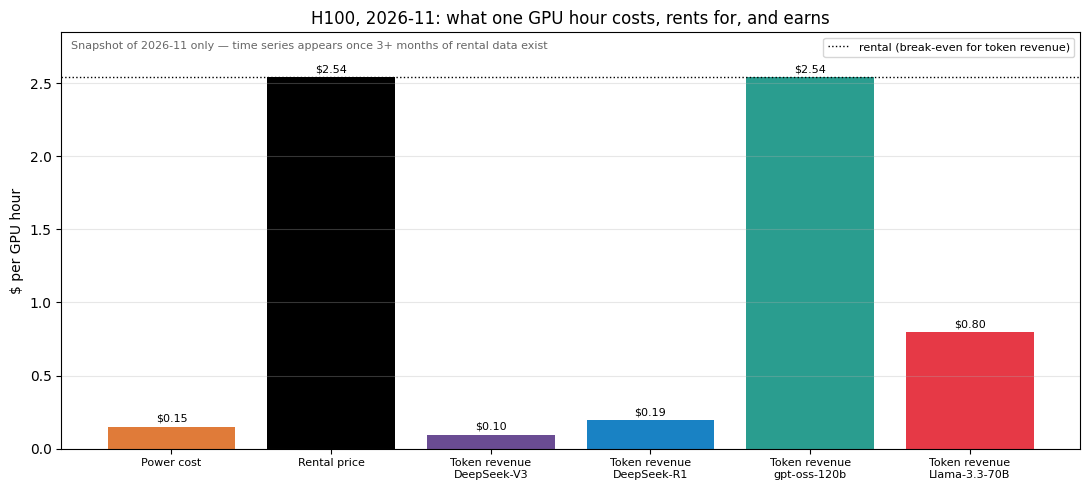

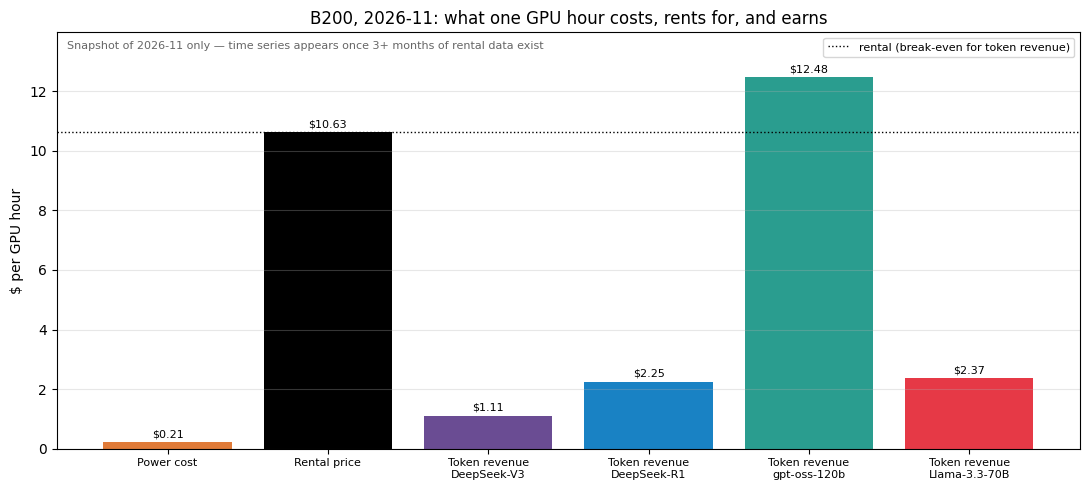

In [18]:
import matplotlib.dates as mdates

COLORS = {"power": "#E07B39", "hardware": "#8C8C8C", "compute_spread": "#3A6EA5",
          "inference_spread": "#4C9A6A", "inference_spread_neg": "#C0392B", "rental": "black"}
MODEL_COLORS = dict(zip(MODEL_NAMES, ["#6A4C93", "#1982C4", "#2A9D8F", "#E63946", "#F4A261", "#8D99AE"]))
GPU_COLORS = dict(zip(GPUS, ["#264653", "#E9C46A", "#9C6644", "#457B9D"]))

# With fewer months than this, charts switch from lines over time to a bar snapshot of the latest month.
# (A line chart of one month is a single dot on an empty axis.) Add history to
# data/manual/gpu_list_prices.csv, or keep collecting Vast snapshots, to get the time-series views.
MIN_MONTHS_FOR_LINES = 3


def n_months(df):
    return df["month"].nunique()


def snapshot_note(ax, month):
    ax.text(0.01, 0.98, f"Snapshot of {month} only — time series appears once {MIN_MONTHS_FOR_LINES}+ months of rental data exist",
            transform=ax.transAxes, va="top", ha="left", fontsize=8, color="#666")


def format_time_axis(ax, x):
    # Fit the x-axis to the data instead of matplotlib's default multi-year padding.
    x = pd.DatetimeIndex(x)
    pad = pd.Timedelta(days=15)
    ax.set_xlim(x.min() - pad, x.max() + pad)
    loc = mdates.AutoDateLocator(minticks=4, maxticks=10)
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))


def money_labels(ax, bars, values):
    fmt = lambda v: "n/a" if pd.isna(v) else ("−" if v < -0.005 else "") + f"${abs(v):,.2f}"
    ax.bar_label(bars, labels=[fmt(v) for v in values],
                 fontsize=8, padding=2)


def plot_chain(gpu):
    d_all = panel[panel.gpu == gpu]
    if d_all.empty:
        print("no data for", gpu); return
    base = d_all.drop_duplicates("month").set_index("month").sort_index()
    fig, ax = plt.subplots(figsize=(11, 5))

    if len(base) < MIN_MONTHS_FOR_LINES:
        m = base.index.max()
        cur = d_all[d_all.month == m].set_index("model")["token_rev"]
        labels = ["Power cost", "Rental price"] + [f"Token revenue\n{s}" for s in MODEL_NAMES]
        vals = [base.loc[m, "power"], base.loc[m, "rental"]] + [cur.get(s, np.nan) for s in MODEL_NAMES]
        colors = [COLORS["power"], COLORS["rental"]] + [MODEL_COLORS[s] for s in MODEL_NAMES]
        bars = ax.bar(labels, vals, color=colors)
        money_labels(ax, bars, vals)
        ax.axhline(base.loc[m, "rental"], color="black", lw=1, ls=":", label="rental (break-even for token revenue)")
        ax.set_title(f"{gpu}, {m}: what one GPU hour costs, rents for, and earns")
        ax.tick_params(axis="x", labelsize=8)
        ax.margins(y=0.12)
        snapshot_note(ax, m)
        ax.legend(fontsize=8, loc="upper right")
    else:
        x = base.index.to_timestamp()
        ax.plot(x, base["power"], color=COLORS["power"], lw=2.5, label="Power cost", marker="o", ms=3)
        ax.plot(x, base["rental"], color=COLORS["rental"], lw=2.5, label="Rental price", marker="o", ms=3)
        for s in MODEL_NAMES:
            d = d_all[d_all.model == s].set_index("month").sort_index()["token_rev"]
            ax.plot(d.index.to_timestamp(), d, color=MODEL_COLORS[s], lw=1.5, ls="--", marker="o", ms=3,
                    label=f"Token revenue: {s}")
        format_time_axis(ax, x)
        ax.set_title(f"{gpu}: what one GPU hour costs, rents for, and earns")
        ax.legend(fontsize=8, ncol=2, loc="upper right")

    ax.set_ylabel("$ per GPU hour"); ax.grid(alpha=0.3, axis="y")
    stamp(ax, ["power", "compute", "tokens", "throughput"])
    fig.tight_layout(); fig.savefig(FIG / f"chain_{gpu}.png", dpi=160)
    plt.show()

for g in GPUS:
    plot_chain(g)

**How to read this chart.** For each GPU, it sets the three numbers that make up the chain side by side, all in dollars per GPU hour: what the electricity costs (orange), what the GPU rents for on the market (black), and how much a renter could earn by selling tokens from each model (one colour per model). The dotted line marks the rental price, so any model whose token revenue bar falls short of it loses money for someone renting the GPU to serve it. With fewer than three months of rental data the chart shows a single-month snapshot; once more history is added it becomes a line chart over time.

**What it shows (2026-11).** Power is a rounding error: about $0.15 an hour on an H100 against a $2.54 rental (6%), and $0.21 against $10.63 on a B200 (2%). Token revenue varies far more by model than by GPU. gpt-oss-120b earns roughly its rental cost on both chips ($2.54 on H100, $12.48 on B200), while Llama-3.3-70B and the two DeepSeek models earn well below rent, with DeepSeek-V3 on H100 lowest at about $0.10 an hour.

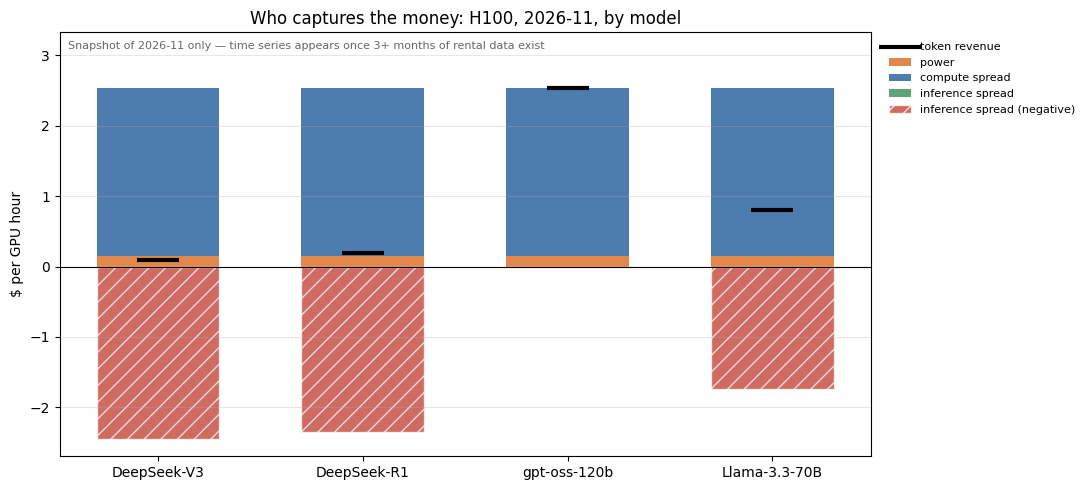

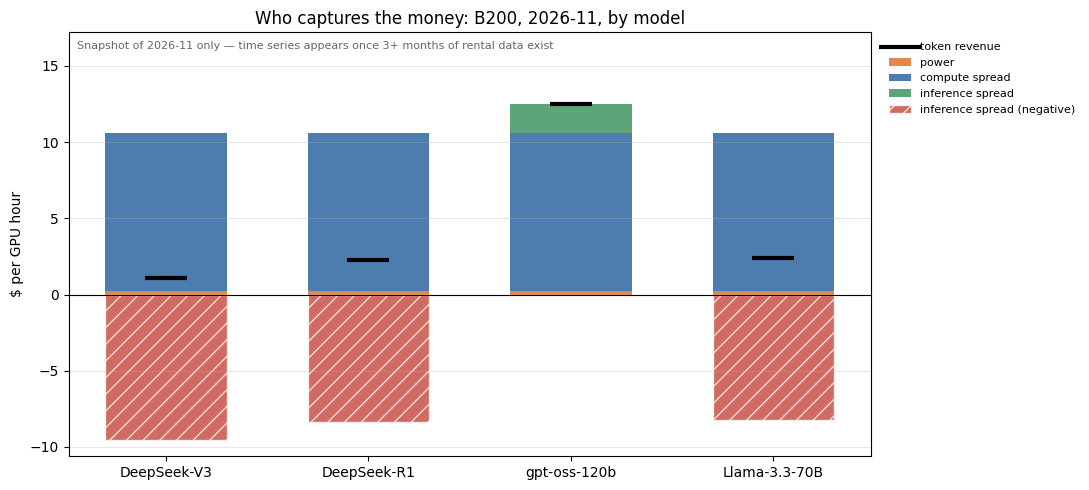

In [19]:
def capture_parts():
    # power (+ hardware) + compute spread = rental; rental + inference spread = token revenue
    return ["power", "hardware", "compute_spread", "inference_spread"] if INCLUDE_HARDWARE \
        else ["power", "compute_spread", "inference_spread"]


def stacked_bars(ax, x, d, parts, width=0.6, label=True):
    # Positive pieces stack up from 0, negative pieces stack down from 0 (so a money-losing
    # inference spread shows below the axis instead of vanishing).
    up, down = np.zeros(len(d)), np.zeros(len(d))
    for p in parts:
        v = d[p].fillna(0).to_numpy()
        pos, neg = np.clip(v, 0, None), np.clip(v, None, 0)
        name = p.replace("_", " ")
        ax.bar(x, pos, width, bottom=up, color=COLORS[p], alpha=0.9, label=name if label else None)
        if (neg < 0).any():
            ax.bar(x, neg, width, bottom=down, color=COLORS.get(f"{p}_neg", COLORS[p]), alpha=0.75,
                   hatch="//", edgecolor="white", label=f"{name} (negative)" if label else None)
        up, down = up + pos, down + neg
    ax.scatter(x, d["token_rev"], marker="_", s=900, lw=3, color="black", zorder=5,
               label="token revenue" if label else None)


def plot_value_capture(gpu, models=None):
    models = models or MODEL_NAMES
    d_all = panel[(panel.gpu == gpu) & panel.model.isin(models)].dropna(subset=["token_rev"])
    if d_all.empty:
        print("no data for", gpu); return
    parts = capture_parts()

    if n_months(d_all) < MIN_MONTHS_FOR_LINES:
        m = d_all.month.max()
        d = d_all[d_all.month == m].set_index("model").reindex(models).dropna(subset=["token_rev"])
        fig, ax = plt.subplots(figsize=(11, 5))
        stacked_bars(ax, np.arange(len(d)), d, parts)
        ax.set_xticks(np.arange(len(d)), d.index)
        ax.axhline(0, color="black", lw=0.8)
        ax.set_title(f"Who captures the money: {gpu}, {m}, by model")
        snapshot_note(ax, m)
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo, hi + 0.15 * (hi - lo))   # headroom so the note never sits on a bar
        ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
        axes = [ax]
    else:
        ncols = 2 if len(models) > 1 else 1
        nrows = int(np.ceil(len(models) / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(13, 3.6 * nrows), sharey=True, squeeze=False)
        axes = axes.ravel()
        for i, (ax, s) in enumerate(zip(axes, models)):
            d = d_all[d_all.model == s].set_index("month").sort_index()
            if d.empty:
                ax.set_title(f"{s}: no data"); continue
            x = d.index.to_timestamp()
            pos = d[parts].clip(lower=0).fillna(0)
            ax.stackplot(x, [pos[p] for p in parts], colors=[COLORS[p] for p in parts], alpha=0.85,
                         labels=[p.replace("_", " ") if i == 0 else "_nolegend_" for p in parts])
            neg = d["inference_spread"].clip(upper=0).fillna(0)
            if (neg < 0).any():
                ax.fill_between(x, 0, neg, color=COLORS["inference_spread_neg"], alpha=0.6,
                                label="inference spread (negative)" if i == 0 else None)
            ax.plot(x, d["token_rev"], color="black", lw=1.5, label="token revenue" if i == 0 else None)
            ax.axhline(0, color="black", lw=0.8)
            format_time_axis(ax, x)
            ax.set_title(s, fontsize=10)
        for ax in axes[len(models):]:
            ax.set_visible(False)
        fig.suptitle(f"Who captures the money: {gpu}")
        fig.legend(*axes[0].get_legend_handles_labels(), fontsize=8, loc="lower center",
                   ncol=len(parts) + 2, bbox_to_anchor=(0.5, -0.02))
        axes = list(axes[:len(models)])

    for ax in axes:
        ax.set_ylabel("$ per GPU hour"); ax.grid(alpha=0.3, axis="y")
        stamp(ax, ["power", "compute", "tokens", "throughput"])
    fig.tight_layout(); fig.savefig(FIG / f"value_capture_{gpu}.png", dpi=160, bbox_inches="tight")
    plt.show()

for g in GPUS:
    plot_value_capture(g)

**How to read this chart.** Each bar splits one GPU hour of token revenue into who keeps it. From the bottom: the power bill (orange), the compute spread kept by whoever owns and rents out the GPU (blue), and the inference spread kept by whoever rents the GPU and sells tokens (green). Orange plus blue always adds up to the rental price. When token revenue (black tick) is below the rental price, the inference spread is negative and is drawn as a red hatched bar below zero: that is the renter's loss per hour. With three or more months of data, this becomes one stacked-area panel per model over time.

**What it shows (2026-11).** Almost all of the money sits in the compute spread: the GPU owner keeps about $2.39 of every H100 hour and $10.42 of every B200 hour after power. The inference layer is negative for DeepSeek-V3, DeepSeek-R1 and Llama-3.3-70B on both GPUs, so at today's prices whoever rents the GPU to sell those tokens pays more in rent than they earn. gpt-oss-120b is the exception: break-even on H100 and about +$1.85 an hour on B200.

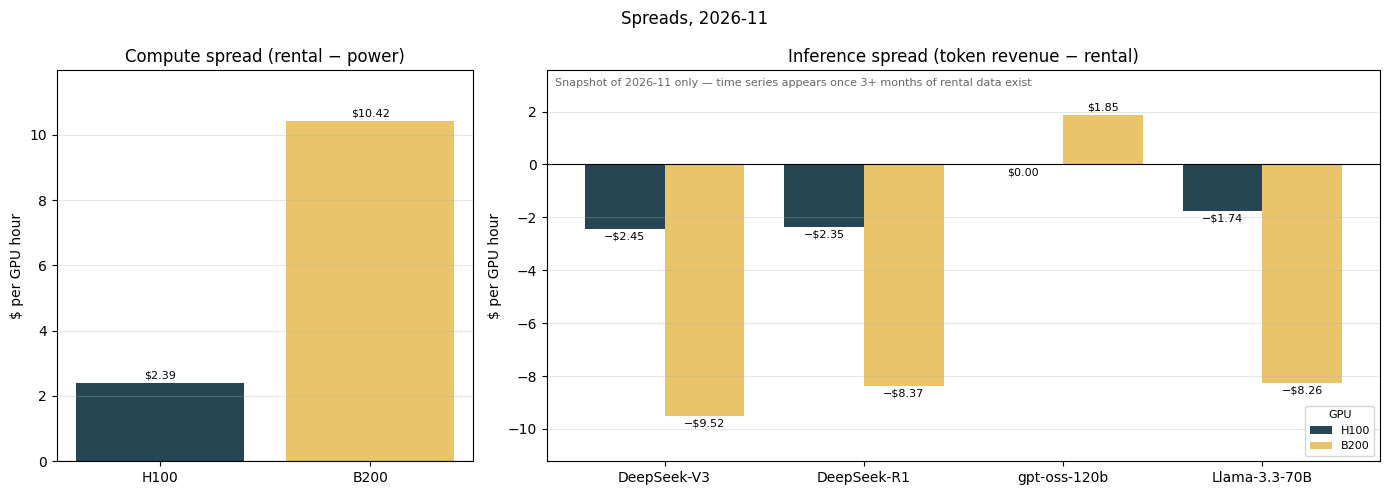

In [20]:
def plot_spreads():
    fig, (ax_c, ax_i) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 2]})

    if n_months(panel) < MIN_MONTHS_FOR_LINES:
        m = panel.month.max()
        cur = panel[panel.month == m]
        # Compute spread: one bar per GPU
        comp = cur.drop_duplicates("gpu").set_index("gpu").reindex(GPUS)["compute_spread"]
        bars = ax_c.bar(comp.index, comp, color=[GPU_COLORS[g] for g in comp.index])
        money_labels(ax_c, bars, comp)
        # Inference spread: grouped bars, models on x, one bar per GPU
        inf = cur.pivot_table(index="model", columns="gpu", values="inference_spread").reindex(index=MODEL_NAMES, columns=GPUS)
        w = 0.8 / len(GPUS)
        xs = np.arange(len(inf))
        for k, g in enumerate(GPUS):
            b = ax_i.bar(xs + (k - (len(GPUS) - 1) / 2) * w, inf[g], w, color=GPU_COLORS[g], label=g)
            money_labels(ax_i, b, inf[g])
        ax_i.set_xticks(xs, inf.index)
        ax_i.legend(fontsize=8, title="GPU", title_fontsize=8, loc="lower right")
        for ax in (ax_c, ax_i):
            ax.margins(y=0.15)
        snapshot_note(ax_i, m)
        fig.suptitle(f"Spreads, {m}")
    else:
        for g in GPUS:
            d = panel[panel.gpu == g].drop_duplicates("month").set_index("month").sort_index()["compute_spread"]
            ax_c.plot(d.index.to_timestamp(), d, lw=2, marker="o", ms=3, color=GPU_COLORS[g], label=g)
            for s in MODEL_NAMES:
                d = panel[(panel.gpu == g) & (panel.model == s)].set_index("month").sort_index()["inference_spread"]
                # colour = model, line style = GPU, so 8 series stay tellable apart
                ax_i.plot(d.index.to_timestamp(), d, lw=1.4, marker="o", ms=3, color=MODEL_COLORS[s],
                          ls=["-", "--", ":", "-."][GPUS.index(g) % 4], label=f"{g} · {s}")
        x = panel.month.drop_duplicates().sort_values().dt.to_timestamp()
        for ax in (ax_c, ax_i):
            format_time_axis(ax, x)
        ax_c.legend(fontsize=8)
        ax_i.legend(fontsize=7, ncol=2)

    ax_c.set_title("Compute spread (rental − power" + (" − hardware" if INCLUDE_HARDWARE else "") + ")")
    ax_i.set_title("Inference spread (token revenue − rental)")
    for ax, layers in [(ax_c, ["power", "compute"]), (ax_i, ["compute", "tokens", "throughput"])]:
        ax.axhline(0, color="black", lw=0.8)
        ax.set_ylabel("$ per GPU hour"); ax.grid(alpha=0.3, axis="y")
        stamp(ax, layers)
    fig.tight_layout(); fig.savefig(FIG / "spreads.png", dpi=160)
    plt.show()

plot_spreads()

**How to read this chart.** This puts the two spreads side by side. The left panel is the compute spread (rental price minus power, plus hardware cost when that is switched on), which belongs to the GPU owner; there is one value per GPU because it doesn't depend on the model. The right panel is the inference spread (token revenue minus rental price) for every GPU and model pair, which belongs to the token seller. Bars or lines above zero mean that layer makes money; below zero means it loses money.

**What it shows (2026-11).** The compute spread is positive and large on both chips ($2.39 an hour on H100, $10.42 on B200). The inference spread is negative in seven of the eight pairs, from about −$1.74 (Llama-3.3-70B on H100) to −$9.52 (DeepSeek-V3 on B200). The only positive pair is gpt-oss-120b on B200 (+$1.85). The B200 losses are bigger mainly because its Vast.ai rental price ($10.63 an hour, from only 16 offers) is high, not because it serves tokens worse: the B200 has the higher token revenue for every model. All figures are asking and list prices, not settled trades.

### Sensitivity: how fragile is the inference spread?
The two softest assumptions are how hard the GPU is actually driven (token load factor) and the input:output mix.
This grid shows the latest month's inference spread across both.

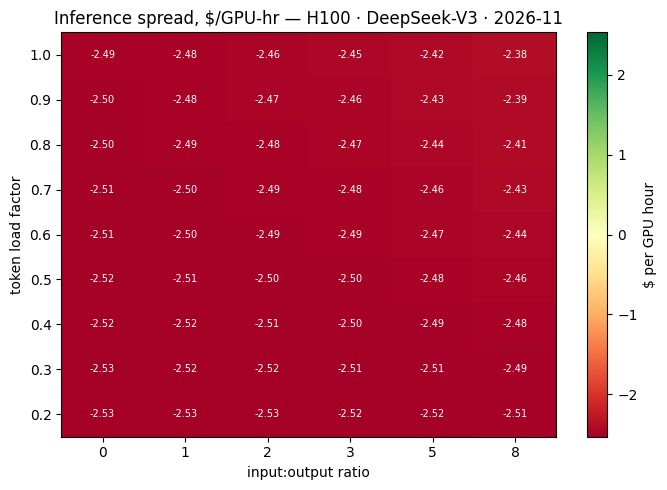

input:output ratio,0,1,2,3,5,8
token load factor,,,,,,
0.2,-2.531975,-2.529138,-2.526300,-2.523463,-2.517788,-2.509275
0.3,-2.526852,-2.522596,-2.518339,-2.514083,-2.505570,-2.492801
0.4,-2.521729,-2.516054,-2.510378,-2.504703,-2.493353,-2.476328
0.5,-2.516605,-2.509511,-2.502418,-2.495324,-2.481136,-2.459854
0.6,-2.511482,-2.502969,-2.494457,-2.485944,-2.468919,-2.443381
0.7,-2.506359,-2.496427,-2.486496,-2.476564,-2.456701,-2.426907
0.8,-2.501235,-2.489885,-2.478535,-2.467185,-2.444484,-2.410433
0.9,-2.496112,-2.483343,-2.470574,-2.457805,-2.432267,-2.393960
1.0,-2.490988,-2.476801,-2.462613,-2.448425,-2.420049,-2.377486


In [21]:
def sensitivity(gpu="H100", model="DeepSeek-V3",
                loads=np.round(np.arange(0.2, 1.01, 0.1), 1), ratios=(0, 1, 2, 3, 5, 8)):
    month = panel.dropna(subset=["token_rev"]).month.max()
    tps = throughput_by_month(gpu, model)[month]
    obs = token_obs[(token_obs.series == model) & (token_obs.month == month)]
    p_in, p_out = obs["usd_per_m_input"].median(), obs["usd_per_m_output"].median()
    rent = rental.loc[month, gpu]
    grid = pd.DataFrame({r: [tps * l * 3600 / 1e6 * (p_out + r * p_in) - rent for l in loads] for r in ratios},
                        index=loads)
    grid.index.name, grid.columns.name = "token load factor", "input:output ratio"
    fig, ax = plt.subplots(figsize=(7, 5))
    lim = np.nanmax(np.abs(grid.values))
    im = ax.imshow(grid.values, cmap="RdYlGn", vmin=-lim, vmax=lim, aspect="auto", origin="lower")
    ax.set_xticks(range(len(ratios)), ratios); ax.set_yticks(range(len(loads)), loads)
    ax.set_xlabel(grid.columns.name); ax.set_ylabel(grid.index.name)
    for i in range(len(loads)):
        for j in range(len(ratios)):
            v = grid.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(v) > 0.6 * lim else "black")
    ax.set_title(f"Inference spread, $/GPU-hr — {gpu} · {model} · {month}")
    fig.colorbar(im, ax=ax, label="$ per GPU hour")
    stamp(ax, ["compute", "tokens", "throughput"])
    fig.tight_layout(); fig.savefig(FIG / f"sensitivity_{gpu}_{model}.png", dpi=160)
    plt.show()
    return grid

sensitivity()

**How to read this chart.** This heatmap tests how sensitive the inference spread for one GPU and model pair (here H100 serving DeepSeek-V3, latest month) is to the two softest assumptions. Rows are the token load factor (achieved throughput as a share of benchmark throughput). Columns are the input to output token ratio (how many input tokens are billed for each output token). Each cell is the inference spread in dollars per GPU hour: green means the renter makes money and red means they lose it, with zero at the centre of the colour scale.

**What it shows (2026-11).** Every cell is red, from about −$2.53 to −$2.38 an hour, so no plausible load factor or input mix makes this pair profitable. Neither assumption drives the result; the benchmark throughput, which the heatmap holds fixed, does. That throughput is only about 15 output tokens per second per GPU (InferenceX, at 50 tokens per second per user). At the notebook's 0.6 load factor, breaking even against a $2.54 rental would take about 386 tokens per second per GPU, roughly 26 times more. That is consistent with DeepSeek-V3 being too large to serve efficiently on H100s at interactive speeds.

- What this chart measures is the inference spread: token revenue minus the H100 rental price, per GPU hour. It describes someone who rents an H100 at today's vast price of $2.54/hr and sells DeepSeek-V3 tokens at today's OpenRouter prices. The operator earns about $0.10 an hour against $2.54 of rent, a loss of $2.45 per GPU hour. 

- 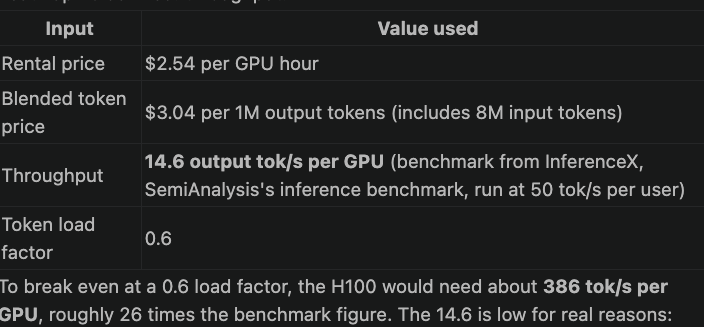

- The H100 struggles with DeepSeek. The model has a 671B parameters and does not fit on one 8-GPU H100 server at FP8 so the setup spans multiple servers. The benchmark also counts the GPUs used for prefill (processing the prompt) not just those generating tokens.

- The speed is demanding for this hardware. 50 tok/s per user is a high bar being set for H100s running this model. At a lower speed target the same hardware serves many more users at once and throughput per GPU clinbs sharply. 

- Summary: At market prices renting the H100s to serve DeepSeek at interactive speeds does not pay. That matches the industry where DeepSeek is mostly served on H200s and B200s or larger clusters. 

## 7. Findings (fill in once real data is in)
- **Power is a rounding error / is not a rounding error:** power is __% of the H100 rental price.
- **Compute spread:** H100 rental minus power went from $__ (2023) to $__ (now). B200: __.
- **Inference spread:** at our base assumptions, serving DeepSeek V3 on an H100 earns $__ more / less than renting the GPU costs.
- **Who captures the money:** __.
- **List vs. settled:** our list-price H100 ($__) vs. Ornn OCPI ($__ on __). Implication: __.
- **What this means for compute futures:** __.

## 8. Data checklist
Run this to see which layers are still synthetic.

In [22]:
status = {
    "power (EIA)": "SYNTHETIC" if "power" in SYNTHETIC_LAYERS else "real",
    "compute (list prices + Vast)": "SYNTHETIC" if "compute" in SYNTHETIC_LAYERS else "real",
    "tokens (OpenRouter / manual)": "SYNTHETIC" if "tokens" in SYNTHETIC_LAYERS else "real",
    "throughput (InferenceX)": "SYNTHETIC" if "throughput" in SYNTHETIC_LAYERS else "real",
}
pd.Series(status, name="status").to_frame()

,status
power (EIA),real
compute (list prices + Vast),real
tokens (OpenRouter / manual),real
throughput (InferenceX),real


# The AI Spark Spread

## The idea
Power traders track the **spark spread**: the gap between what electricity sells for and what the gas to make it costs. A positive spread means running the power plant pays.

This project builds the AI version for **one GPU hour**:

> **cost of electricity → price to rent the GPU → revenue from selling tokens on it**

- Each layer is in **$ per GPU hour**, so all three can be compared directly.
- Two spreads fall out of the chain:
  - **Compute spread** (kept by the GPU owner) = rental price − electricity (− hardware, later)
  - **Inference spread** (kept by the token seller) = token revenue − rental price
- Goals:
  1. Track how these margins have changed from **2023 to now**.
  2. Work out **which layer captures the money**: the power supplier, the GPU owner, or the token seller.

---

## Scope

### Which GPUs
- **NVIDIA H100**: main case. **NVIDIA B200**: second case. These were Ornn's first two contracts.
- H100 rental offers include the SXM, NVL and PCIe variants, priced per GPU.

### Open-source models
| Model | Why it's included | Notes |
|---|---|---|
| DeepSeek-V3 | Large MoE chat model, widely served | No InferenceX runs of its own; uses DeepSeek-R1's throughput (same architecture) |
| DeepSeek-R1 | Reasoning model, same base as V3 | |
| gpt-oss-120b | OpenAI's open-weight MoE, very efficient to serve | FP4 runs preferred |
| Llama 3.3 70B | Dense model, a long price history through the Llama 2 → 3 → 3.1 → 3.3 line | FP8 runs preferred |

- **Why open-source:** many providers serve the same model, so there's a real market price, and public throughput benchmarks exist. Closed models have one seller and unknown hardware.
- **Model lineage:** to cover 2023 onward, older versions are counted as the same series (for example Llama-2-70B → Llama-3.3-70B, DeepSeek-V2 → V3).

### Timeline
- **2023-01 to today**, monthly.
- The live daily collection started **Nov 2026**. Earlier months rely on historical sources (Wayback snapshots, hand-checked price files), which are still being filled in.

### Costs included
- **Now:** electricity only.
- **Later (v2):** hardware cost, meaning the server's purchase price spread over its useful life. Planned settings: 5-year life, 70% utilization. Not turned on yet, so the GPU owner's margin is currently *before* paying for the GPUs.

---

## Layer 1: Power ($ per GPU hour of electricity)

**Formula**
> power $/GPU-hr = kW per GPU × server load factor × PUE × $/kWh

### Electricity price
- **Source:** EIA API v2 (eia.gov/opendata), electricity retail sales: monthly average price by state and sector.
- **Pulled:** states US, VA, TX, GA, AZ, OR; sectors industrial (IND) and commercial (COM).
- **In use:** US average, industrial. Latest is **$0.0952/kWh (Sep 2026)**.
- EIA publishes about **two months late**, so the latest month is carried forward.
- **Alternative:** ERCOT (Texas) or PJM (Mid-Atlantic, which includes Virginia's data center cluster) wholesale/spot prices instead of retail. Big data centers often buy closer to wholesale.

### GPU power draw
- Chip power: H100 ≈ **700 W**, B200 ≈ **1,000 W**.
- The whole server counts, not just the chip: CPUs, memory, networking and fans. Modeled on an 8-GPU server:
  - H100 server: **10.2 kW** → 1.275 kW per GPU
  - B200 server: **14.3 kW** → 1.79 kW per GPU
- **Server load factor: 0.8.** Servers don't run at maximum power all the time.

### PUE (data center overhead)
- **PUE = total facility power ÷ IT power.** It covers cooling, power conversion and lighting.
- **Industry average: 1.56** (Uptime Institute annual survey). **In use.**
- **Hyperscaler: ~1.10** (Google / Meta sustainability reports).

### Result today
| | H100 | B200 |
|---|---|---|
| Electricity per GPU hour | **$0.15** | **$0.21** |

→ Power is a small slice of the chain: about 6% of the H100 rental price and 2% of the B200's.

---

## Layer 2: Compute ($ per GPU hour of rental)

**Formula**
> rental $/GPU-hr = median asking price across offers that month

### Sources
- **Vast.ai marketplace API.** On-demand offers for H100 and B200, collected **daily**. Price per GPU = offer price ÷ number of GPUs.
- **Historical list prices** from Wayback Machine snapshots of neocloud and cloud pricing pages: Lambda, CoreWeave, AWS. These fill in 2023 onward.
- **Epoch AI ML hardware dataset:** launch prices and specs.
- **Ornn and Silicon Data** public price indexes: used only to cross-check and credited. **Not used as inputs.**

### Result today
| | H100 | B200 |
|---|---|---|
| Median rental | **$2.54** (38 offers) | **$10.63** (13 offers) |

→ The B200 figure comes from a thin market (few offers), so treat it as rough.

---

## Layer 3: Tokens ($ earned per GPU hour)

**Formula**
> token revenue $/GPU-hr = output tok/s per GPU × token load factor × 3,600 ÷ 1,000,000 × blended price
>
> blended price = output $/1M + (input tokens per output token × input $/1M)

### Token prices
- **OpenRouter models API:** input and output prices for each model from every provider, collected **daily**. The median across providers is used.
- **Wayback snapshots** of OpenRouter and provider pages for history.
- **Artificial Analysis:** price and speed by provider (used in the notebook as a cross-check).
- **Epoch AI LLM inference price trends:** the long-run picture of how fast token prices fall.

### Throughput per GPU
- **Source:** SemiAnalysis **InferenceX** benchmark runs (exported by hand).
- **The trade-off:** a GPU can serve many users slowly or a few users quickly. Total throughput depends heavily on the speed each user gets.
- **Rule used:** the best output tok/s per GPU at **50 tok/s per user**, read off the benchmark's frontier of speed per user vs. throughput per GPU.
- Speculative decoding excluded. Preferred serving software: vLLM, or Dynamo-TRT for DeepSeek.

### Assumptions
- **Input tokens per output token: 8.** Matches the benchmark's 8K-in / 1K-out workload. Input is billed too, so this raises revenue.
- **Token load factor: 0.6.** Real traffic is uneven, so a GPU achieves about 60% of benchmark throughput on average.

### Result today ($ per GPU hour)
| GPU | Model | tok/s per GPU | Token revenue | Rental | **Inference spread** |
|---|---|---|---|---|---|
| H100 | DeepSeek-V3 | 15 | $0.10 | $2.54 | **−$2.45** |
| H100 | DeepSeek-R1 | 15 | $0.19 | $2.54 | **−$2.35** |
| H100 | gpt-oss-120b | 988 | $2.77 | $2.54 | **+$0.23** |
| H100 | Llama 3.3 70B | 163 | $0.80 | $2.54 | **−$1.74** |
| B200 | DeepSeek-V3 | 169 | $1.11 | $10.63 | **−$9.52** |
| B200 | DeepSeek-R1 | 169 | $2.25 | $10.63 | **−$8.37** |
| B200 | gpt-oss-120b | 4,855 | $13.63 | $10.63 | **+$3.01** |
| B200 | Llama 3.3 70B | 485 | $2.37 | $10.63 | **−$8.26** |

---

## What the numbers say so far
1. **The GPU owner captures most of the money.** The compute spread is about $2.39/hr on H100 and $10.42/hr on B200, before hardware cost.
2. **Power is a minor cost:** $0.15–0.21 per GPU hour.
3. **Selling tokens at public prices only pays for gpt-oss-120b**, the one model efficient enough to serve. Renting a GPU to serve DeepSeek or Llama at these prices loses money.
4. **Throughput decides the token seller's result.** A 5–10× swing in tok/s (from serving setup or speed per user) can flip a loss into a profit. Use the website's calculator to test this.

---

## The pipeline and website
- **Live site:** https://macisekander.github.io/ai-spark-spread/
- **Repo:** https://github.com/MaciSekander/ai-spark-spread
- **How it updates:** GitHub Actions runs daily at 06:17 UTC.
  1. `spark.collect` fetches today's Vast.ai and OpenRouter prices (EIA weekly) and appends them to the history files.
  2. `spark.build` recomputes the panel and writes `spark.json`.
  3. The site (Observable Framework) is rebuilt and deployed to GitHub Pages.
- The history grows by one day per run and is committed to the repo.
- API keys live in GitHub repository secrets and never reach the site.
- **Pages:** Today's spread (charts plus the break-even calculator) and Methods & sources.
- **Research notebook:** `notebooks/01_spark_spread_research.ipynb`. Same math as the site, with charts and a description under each one.
- Throughput updates are manual: download new InferenceX exports, run `python -m spark.throughput`, then commit.

---

## Caveats
- **Asking prices, not settled trades.** Rental and token prices are public list or asking prices. Reserved and long-term contracts are often cheaper.
- **Thin B200 market:** few marketplace offers.
- **Retail vs. wholesale power:** large data centers may pay less than the EIA retail average.
- **Throughput benchmarks vary widely** with hardware setup, software and speed per user.
- **Hardware cost not included yet**, so the owner's margin is overstated.

---

## Open questions / to think through
- [ ] **H100 DeepSeek throughput (15 tok/s per GPU) looks very low.** Is it a multi-node setup in the benchmark? Is 50 tok/s per user the right target for a reasoning model?
- [ ] **Speed per user:** should each model get its own target (e.g. lower for batch or reasoning workloads)?
- [ ] **Hardware cost (v2):** which server prices to use (Epoch, SemiAnalysis estimates)? 5 years or 3–4 for the useful life?
- [ ] **Power:** switch to ERCOT/PJM wholesale for a "large buyer" case? Show both retail and wholesale?
- [ ] **Hyperscaler case:** PUE 1.10 plus wholesale power as a second scenario?
- [ ] **Rental history 2023–2026:** finish the Wayback list-price collection (Lambda, CoreWeave, AWS).
- [ ] **Token price history:** Wayback snapshots of OpenRouter, plus Epoch trends for the long run.
- [ ] **B200 rental:** add list prices from neoclouds to supplement the thin Vast.ai market?
- [ ] **Is the token seller really renting?** Big providers own their GPUs. Maybe compare token revenue to power + hardware instead.
